# CNN Model Training for PCOS Detection

This notebook builds and trains a Convolutional Neural Network (CNN) from scratch to classify ultrasound images into:
- noninfected
- infected

The model is built using TensorFlow/Keras only, following the project requirements.  
The training uses:
- image resizing
- pixel normalization
- training-only augmentation
- class weighting to handle imbalance
- dropout and L2 regularization to reduce overfitting
- early stopping and learning rate reduction

In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

In [40]:
train_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/train_df.csv")
val_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/val_df.csv")
test_df = pd.read_csv("C:\\Users\\MHawa\\OneDrive\\Desktop\\DL project\\data\\processed/test_df.csv")

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

train_df.head()

Train: (8248, 5)
Validation: (1768, 5)
Test: (1768, 5)


,image_path,label,width,height,label_encoded
0,data\PCOS\PCOS\infected\Image_SETB_242.jpg,infected,225,225,1
1,data\PCOS\PCOS\infected\image10699.jpg,infected,251,261,1
2,data\PCOS\PCOS\noninfected\Image_resize_671 (...,noninfected,315,160,0
3,data\PCOS\PCOS\noninfected\Image_resize_564.jpg,noninfected,848,984,0
4,data\PCOS\PCOS\infected\image10309.jpg,infected,300,300,1


Augmentation is applied only to the training set.  
Validation and test sets are only normalized, which prevents data leakage.

In [42]:
train_df["label_encoded"] = train_df["label_encoded"].astype(str)
val_df["label_encoded"] = val_df["label_encoded"].astype(str)
test_df["label_encoded"] = test_df["label_encoded"].astype(str)

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col="image_path",
    y_col="label_encoded",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_generator = val_test_datagen.flow_from_dataframe(
    val_df,
    x_col="image_path",
    y_col="label_encoded",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_generator = val_test_datagen.flow_from_dataframe(
    test_df,
    x_col="image_path",
    y_col="label_encoded",
    target_size=IMG_SIZE,
    color_mode="rgb",
    class_mode="binary",
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 8248 validated image filenames belonging to 2 classes.
Found 1768 validated image filenames belonging to 2 classes.
Found 1768 validated image filenames belonging to 2 classes.


Class weighting is used to handle the moderate imbalance between the two classes.  
The minority class receives a higher weight, so mistakes on that class are penalized more during training.

In [43]:
class_weights = {
    0: 1.1782857142857144,
    1: 0.8685762426284751
}

class_weights

{0: 1.1782857142857144, 1: 0.8685762426284751}

The CNN architecture is built from scratch.  
It uses convolutional layers to extract spatial features from ultrasound images, batch normalization to stabilize training, max pooling to reduce spatial dimensions, global average pooling to reduce parameters, and dropout/L2 regularization to reduce overfitting.

In [26]:
def build_cnn_model(input_shape=(224, 224, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.4),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


model = build_cnn_model()
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,361 (1.61 MB)

 Trainable params: 422,401 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

Binary cross-entropy is used because this is a binary classification problem.  
The model outputs one probability using a sigmoid activation function.

Accuracy, precision, recall, and AUC are tracked because medical and imbalanced classification problems require more than accuracy alone.

In [27]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [30]:
checkpoint_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/best_pcos_cnn_model.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

In [31]:
EPOCHS = 25

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 785s 3s/step - accuracy: 0.9140 - auc: 0.9748 - loss: 0.3664 - precision: 0.9489 - recall: 0.8991 - val_accuracy: 0.5758 - val_auc: 0.5028 - val_loss: 2.8315 - val_precision: 0.5758 - val_recall: 1.0000 - learning_rate: 1.0000e-04
Epoch 2/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 760s 3s/step - accuracy: 0.9571 - auc: 0.9926 - loss: 0.2537 - precision: 0.9789 - recall: 0.9459 - val_accuracy: 0.5481 - val_auc: 0.7810 - val_loss: 1.9235 - val_precision: 0.5640 - val_recall: 0.9479 - learning_rate: 1.0000e-04
Epoch 3/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 861s 3s/step - accuracy: 0.9669 - auc: 0.9957 - loss: 0.2156 - precision: 0.9813 - recall: 0.9608 - val_accuracy: 0.8665 - val_auc: 0.9273 - val_loss: 1.1164 - val_precision: 1.0000 - val_recall: 0.7682 - learning_rate: 1.0000e-04
Epoch 4/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 775s 3s/step - accuracy: 0.9675 - auc: 0.9957 - loss: 0.2036 - precision: 0.9792 - recall: 0.9640 - val_accuracy: 0.8778 - val_auc: 0.9307 - val_lo

Training stopped early due to EarlyStopping. The validation loss stopped improving after approximately epoch 7, while training accuracy continued increasing. This indicates that the model started to overfit the training data. EarlyStopping restored the best validation weights to improve generalization.

In [32]:
final_model_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/final_pcos_cnn_model.keras"

model.save(final_model_path)

print("Final model saved to:", final_model_path)
print("Best model saved to:", checkpoint_path)

Final model saved to: C:\Users\MHawa\OneDrive\Desktop\DL project\models/final_pcos_cnn_model.keras
Best model saved to: C:\Users\MHawa\OneDrive\Desktop\DL project\models/best_pcos_cnn_model.keras


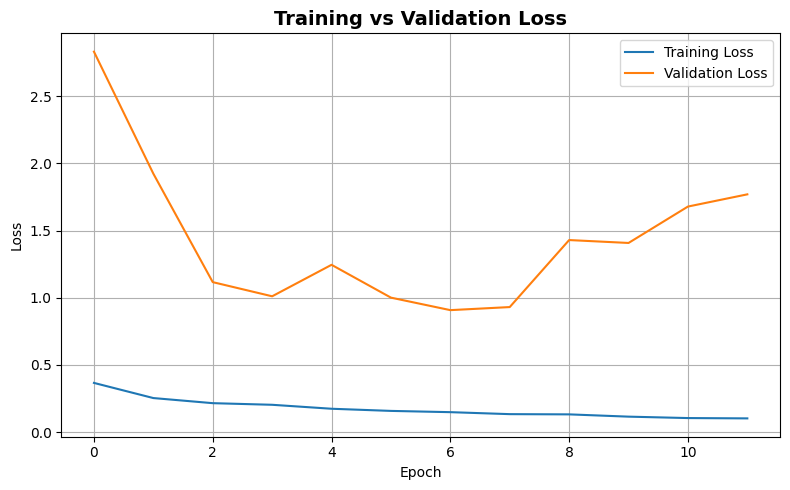

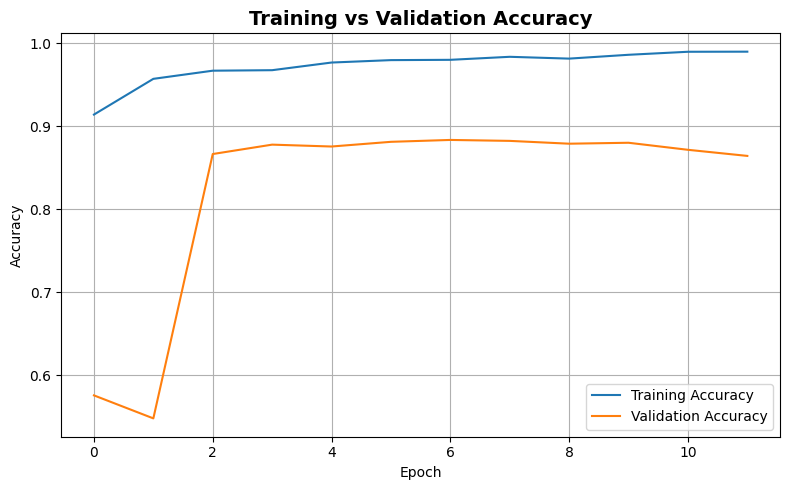

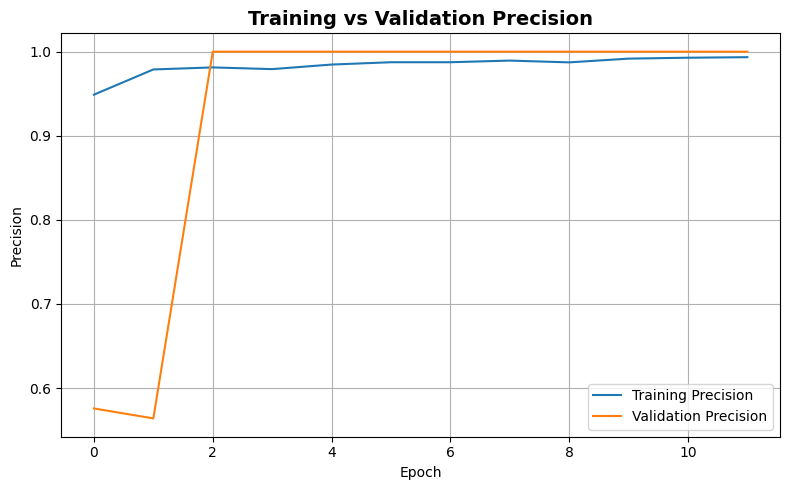

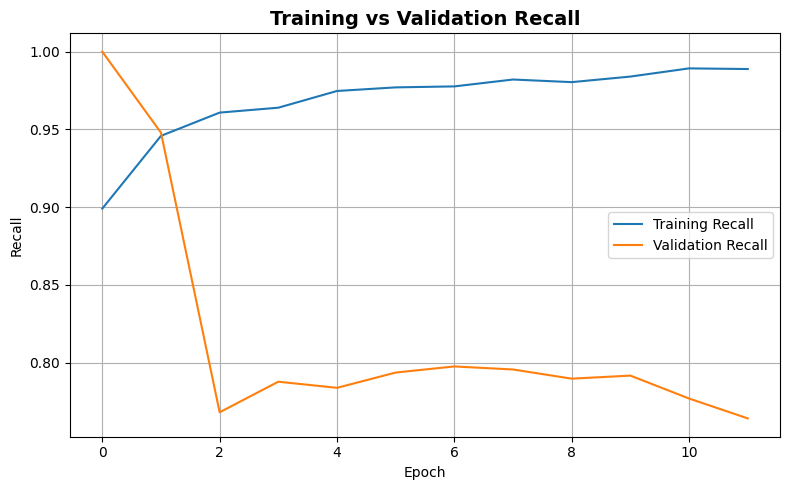

In [33]:
def plot_training_curves(history):
    history_dict = history.history

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["loss"], label="Training Loss")
    plt.plot(history_dict["val_loss"], label="Validation Loss")
    plt.title("Training vs Validation Loss", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_loss.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["accuracy"], label="Training Accuracy")
    plt.plot(history_dict["val_accuracy"], label="Validation Accuracy")
    plt.title("Training vs Validation Accuracy", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_accuracy.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["precision"], label="Training Precision")
    plt.plot(history_dict["val_precision"], label="Validation Precision")
    plt.title("Training vs Validation Precision", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Precision")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_precision.png", dpi=300)
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(history_dict["recall"], label="Training Recall")
    plt.plot(history_dict["val_recall"], label="Validation Recall")
    plt.title("Training vs Validation Recall", fontsize=14, fontweight="bold")
    plt.xlabel("Epoch")
    plt.ylabel("Recall")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.savefig(f"{FIGURES_DIR}/training_validation_recall.png", dpi=300)
    plt.show()

plot_training_curves(history)

## Hyperparameter Tuning

Several hyperparameters were experimentally adjusted to improve validation performance and reduce overfitting.

The following settings were selected after empirical experimentation:
- Image size: 224×224
- Batch size: 32
- Learning rate: 0.0001
- Dropout rate: 0.4
- L2 regularization: 0.001
- Optimizer: Adam
- Epochs: 25 with EarlyStopping

Different configurations were tested, and the selected configuration achieved the best validation AUC and validation loss stability.

In [44]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Improved CNN Experiment (Version 2)

The first CNN experiment showed signs of overfitting:
- training accuracy became much higher than validation accuracy
- validation loss stopped improving after several epochs

Therefore, a second improved CNN experiment was performed with:
- smaller image size
- reduced model complexity
- stronger augmentation
- higher dropout
- L2 regularization

The goal was to improve generalization and reduce overfitting.

In [45]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.9, 1.1],
    fill_mode="nearest"
)

val_test_datagen = ImageDataGenerator(rescale=1./255)

In [46]:
def build_cnn_model(input_shape=(128, 128, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),

        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        layers.Dense(
            128,
            activation="relu",
            kernel_regularizer=regularizers.l2(0.001)
        ),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ])

    return model


model = build_cnn_model()
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,785 (432.75 KB)

 Trainable params: 110,337 (431.00 KB)

 Non-trainable params: 448 (1.75 KB)

In [47]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [48]:
checkpoint_path = r"C:\Users\MHawa\OneDrive\Desktop\DL project\models/best_pcos_cnn_model_v2.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),

    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

In [49]:
EPOCHS = 25

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks
)

Epoch 1/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 204s 759ms/step - accuracy: 0.8567 - auc: 0.9368 - loss: 0.4448 - precision: 0.9097 - recall: 0.8338 - val_accuracy: 0.7545 - val_auc: 0.8949 - val_loss: 0.6805 - val_precision: 0.7031 - val_recall: 0.9931 - learning_rate: 1.0000e-04
Epoch 2/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 193s 748ms/step - accuracy: 0.9186 - auc: 0.9770 - loss: 0.3033 - precision: 0.9570 - recall: 0.8991 - val_accuracy: 0.8179 - val_auc: 0.9454 - val_loss: 0.4352 - val_precision: 0.8858 - val_recall: 0.7849 - learning_rate: 1.0000e-04
Epoch 3/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 210s 813ms/step - accuracy: 0.9363 - auc: 0.9856 - loss: 0.2562 - precision: 0.9689 - recall: 0.9189 - val_accuracy: 0.7607 - val_auc: 0.8916 - val_loss: 1.2960 - val_precision: 1.0000 - val_recall: 0.5845 - learning_rate: 1.0000e-04
Epoch 4/25
258/258 ━━━━━━━━━━━━━━━━━━━━ 191s 739ms/step - accuracy: 0.9444 - auc: 0.9890 - loss: 0.2308 - precision: 0.9716 - recall: 0.9305 - val_accuracy: 0.7274 - val_auc: 0.8

Epoch 2
val_accuracy = 0.8179
val_auc = 0.9454
val_loss = 0.4352
val_recall = 0.7849

A second experiment was conducted using a smaller input size (128×128), a simpler CNN architecture, stronger augmentation, and higher dropout. Although this version trained faster and achieved a validation AUC of 0.9454 at epoch 2, its validation accuracy was lower and validation loss increased rapidly after epoch 2. Therefore, the first CNN model was selected as the final model because it achieved better validation accuracy and more stable validation performance.